# M12.2 — Three-model paired G1 validation evaluation

Adapted from [M12.1 validation evaluation](M12_1_validation_evaluation.ipynb), retaining its metric definitions, frozen train-reference checks, bins and row alignment. Compare M11, M12.1 global weighted MSE and M12.2 marginal weighted MSE on exactly the same 40000 validation rows. All cells are unexecuted; previous outputs and conclusions have not been copied.

Training runs separately. This notebook never trains, predicts, modifies weights, or uses calibration/test/real-event labels or predictions. Train labels are used only to verify/reconstruct train-only geometry and marginal CDFs. Input preprocessing, saved label scaling, architecture and splits remain frozen. No files are written.

Primary acceptance is versus M11; the separate M12.2−M12.1 contrast assesses the incremental change from global to marginal weighting. Marginal/cross-label/discordant analyses are exploratory and cannot substitute for primary criteria or establish causal multi-task interference. The present task explicitly uses M12.2 for marginal weighting despite the older balanced-sampling designation in AGENTS.md.


## 1. Configuration, provenance and strict row alignment

The M11 and M12.1 defaults reuse the exact paths recorded in the existing evaluation. Set `M12_2_VALIDATION_PATH` to the actual completed future archive (absolute or relative to the existing DATA_ROOT). No candidate filename is guessed. The data root uses the unchanged src.paths convention: CBC_PE_DATA_ROOT overrides the M11 config root.

Required trusted NPZ fields: pred_val, y_val (standardized N×3), idx_val (original integer HDF5 row IDs), y_mean, y_std, label_names, available_splits=['val'], checkpoint_file, dataset_path, split_path, label_stats_path, model_config, input_normalization. Object provenance requires allow_pickle=True; load only trusted project artifacts. Embeddings remain unread. All archives are independently sorted by row ID before comparisons; identical ordered targets are required.

Checkpoint names/configs, label order, train-only scalers, frozen split/stat hashes, HDF5 physical-target alignment, architecture and input normalization are checked. Units are solar masses for chirp_mass/total_mass and dimensionless chi_eff. M12 weighting metadata must match its own method: global reference hash for M12.1; per-label marginal reference/weight hashes for M12.2. These metadata checks do not independently prove checkpoint-byte identity. Missing/incompatible provenance stops evaluation rather than silently falling back.


In [1]:
from pathlib import Path
import sys, json, hashlib, copy
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src/paths.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open from the cbc_pe repository")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
from src.models.evaluate import regression_metrics, inverse_standardize
from src.models.sample_weighting import array_hash

CONFIG_PATHS = {"M11": ROOT / "configs/experiments/train_m11_final_G1_500k.json",
                "M12.1": ROOT / "configs/experiments/train_m12_1a_weighted_mse.json",
                "M12.2": ROOT / "configs/experiments/train_m12_2_marginal_alpha0p5.json"}
configs = {m:json.loads(p.read_text()) for m,p in CONFIG_PATHS.items()}
DATA_ROOT = resolve_data_root(config_data_root=configs["M11"].get("data_root"))
DATASET_ID = "M11_final_G1_500k"
LABELS = ["chirp_mass", "total_mass", "chi_eff"]
UNITS = ["Msun", "Msun", "dimensionless"]
MODELS = ["M11", "M12.1", "M12.2"]
PREFIX = {"M11":"M11", "M12.1":"M12_1", "M12.2":"M12_2"}
REFERENCES = ["M11", "M12.1"]
RESULTS = DATA_ROOT / "results" / DATASET_ID

M12_1_VALIDATION_PATH = RESULTS / "m12_1_G1_val_predictions_embeddings.npz"
M12_2_VALIDATION_PATH = RESULTS / "m12_2_G1_val_predictions_embeddings.npz"  # REQUIRED: set to the real future validation NPZ.
BOOTSTRAP_COUNT = 400
BOOTSTRAP_SEED = 123
RUN_BOOTSTRAP = True  # Manually opt in; no bootstrap runs by default.
MIN_COUNT = 30
MIN_2D_COUNT = 100
PERIPHERAL_MASS_MAX_DEGRADATION = 0.02  # Provisional, inherited from current M12.1 evaluation.
CHI_EFF_MAX_DEGRADATION = None  # RMSE fraction; decide prospectively, not after outcomes.
LOW_SNR_MAX_DEGRADATION = None  # RMSE fraction; decide prospectively, not after outcomes.

M11_VALIDATION_PATH = RESULTS / "m11_final_G1_500k_val_predictions_embeddings.npz"
CONTRACT_PATH = ROOT / "notebooks/m12/outputs/m12_0_baseline_contract.json"
PATHS = {key:resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=DATASET_ID,
    file_name=configs["M11"]["dataset"][key], allow_legacy_flat=False)
    for key in ("dataset_file", "split_file", "label_stats_file")}

def require(ok, message):
    if not ok:
        raise ValueError(message)

def file_record(path, small=False):
    path = Path(path)
    require(path.is_file(), f"Missing frozen input: {path}; no generation fallback")
    st = path.stat()
    record = dict(path=str(path), size=st.st_size, mtime_ns=st.st_mtime_ns)
    if small:
        record["sha256"] = hashlib.sha256(path.read_bytes()).hexdigest()
    return record

require(M12_2_VALIDATION_PATH is not None, "Set M12_2_VALIDATION_PATH after predictions are available")
def resolve_prediction_path(value):
    path = Path(value).expanduser()
    return path if path.is_absolute() else DATA_ROOT / path
prediction_paths = {"M11":M11_VALIDATION_PATH,
    "M12.1":resolve_prediction_path(M12_1_VALIDATION_PATH),
    "M12.2":resolve_prediction_path(M12_2_VALIDATION_PATH)}
require(len({p.resolve() for p in prediction_paths.values()}) == 3, "Prediction paths must be distinct")
for model, method, tag in (("M12.1","train_label_mahalanobis","M12_1"),
                           ("M12.2","train_label_marginal","M12_2")):
    expected = copy.deepcopy(configs["M11"])
    expected.pop("data_root", None)
    expected["training"]["sample_weighting"] = dict(method=method, alpha=.5, normalization="train_mean_one")
    expected["outputs"] = configs[model]["outputs"]
    actual = copy.deepcopy(configs[model]); actual.pop("data_root",None)
    require(actual == expected, f"{model}: unexpected scientific config differences")
    require(configs[model]["outputs"]["checkpoint_tag"].startswith(tag), "Wrong checkpoint tag")
# Use geometry/definitions only; historical test metrics and real-event results are not evaluated.
frozen = json.loads(CONTRACT_PATH.read_text())
require(frozen["schema_version"] == 1 and frozen["dataset_id"] == DATASET_ID
        and frozen["labels"] == LABELS, "Wrong M12.0 contract")
# Pin the small split/scaler contracts as well as train geometry; do not trust filenames alone.
for key in ("split_file", "label_stats_file"):
    require(file_record(PATHS[key], True)["sha256"] ==
            frozen["provenance"]["local_artifacts"][key]["sha256"],
            f"Frozen M12.0 artifact content mismatch: {key}")
geometry = frozen["geometry"]
P_EDGES = np.asarray(geometry["edges"], dtype=float)
SNR_EDGES = np.asarray(frozen["definitions"]["snr_edges"], dtype=float)
require(np.array_equal(P_EDGES, [0,20,40,60,80,100]), "Changed percentile bins")
require(np.array_equal(SNR_EDGES, [10,12.5,15,17.5,20,22.5,25]), "Changed SNR bins")
del frozen
provenance = dict(contract=file_record(CONTRACT_PATH, True),
    configs={m:file_record(p, True) for m,p in CONFIG_PATHS.items()},
    artifacts={k:file_record(p, k != "dataset_file") for k,p in PATHS.items()},
    predictions={m:file_record(p) for m,p in prediction_paths.items()},
    split="val", units=dict(zip(LABELS, UNITS)))


In [2]:
with np.load(PATHS["split_file"], allow_pickle=False) as z:
    train_ids = np.sort(z["train_idx"].copy())
    val_ids = np.sort(z["val_idx"].copy())
    require(int(z["seed"].item()) == 123, "Split seed changed")
for name, ids, n in (("train",train_ids,400000), ("val",val_ids,40000)):
    require(ids.shape == (n,) and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == n and ((ids >= 0) & (ids < 500000)).all(), f"Invalid {name} IDs")
require(np.intersect1d(train_ids, val_ids).size == 0, "Train/validation overlap")
require(array_hash(train_ids) == geometry["train_indices_sha256"], "Changed frozen train rows")
with np.load(PATHS["label_stats_file"], allow_pickle=False) as z:
    mean, std = z["y_mean"].copy(), z["y_std"].copy()
    require(z["label_names"].tolist() == LABELS, "Scaler label order")
    require(np.array_equal(np.sort(z["train_idx"]), train_ids), "Scaler train membership")
require(mean.shape == std.shape == (3,) and np.isfinite(mean).all()
        and np.isfinite(std).all() and (std > 0).all(), "Invalid saved scaler")

def load_validation(model):
    cfg = configs[model]
    checkpoint_name = (f"{DATASET_ID}_{cfg['model']['class_name']}_"
        f"{cfg['outputs']['checkpoint_tag']}_{cfg['training']['loss']}_seed123_checkpoint.pt")
    with np.load(prediction_paths[model], allow_pickle=True) as z:
        needed = {"pred_val", "y_val", "idx_val", "y_mean", "y_std", "label_names", "available_splits",
                  "checkpoint_file", "dataset_path", "split_path", "label_stats_path",
                  "model_config", "input_normalization"}
        require(needed <= set(z.files), f"{model}: missing {needed-set(z.files)}")
        require(z["available_splits"].tolist() == ["val"], "Require a validation-only prediction archive")
        require(z["label_names"].tolist() == LABELS, "Prediction label order")
        require(np.array_equal(z["y_mean"], mean) and np.array_equal(z["y_std"], std), "Scaler changed")
        saved = {k:z[k].item() for k in ("checkpoint_file", "dataset_path", "split_path",
                  "label_stats_path", "model_config", "input_normalization")}
        require(Path(saved["checkpoint_file"]).name == checkpoint_name, "Wrong recorded checkpoint")
        for key, local in (("dataset_path","dataset_file"), ("split_path","split_file"),
                           ("label_stats_path","label_stats_file")):
            require(Path(saved[key]).name == PATHS[local].name, "Recorded artifact mismatch")
        mc = saved["model_config"]
        require(mc["dataset_id"] == DATASET_ID and mc["label_names"] == LABELS, "Checkpoint dataset/labels")
        require(mc["class_name"] == cfg["model"]["class_name"]
                and mc["model_kwargs"] == cfg["model"]["kwargs"], "Checkpoint architecture changed")
        require(mc["training_seed"] == 123 and mc["split_seed"] == 123, "Checkpoint seeds changed")
        require(mc["train_size"] == 400000 and mc["val_size"] == 40000
                and mc["cal_size"] == 30000 and mc["test_size"] == 30000, "Checkpoint split sizes")
        require(saved["input_normalization"] == mc["input_normalization"] == cfg["input_normalization"],
                "Input normalization changed")
        if model != "M11":
            w = mc["sample_weighting"]
            for key, value in cfg["training"]["sample_weighting"].items():
                require(w[key] == value, f"Weight provenance: {key}")
            for key in ("train_indices_sha256", "n_train"):
                require(w[key] == geometry[key], f"Training reference differs from M12.0: {key}")
            if model == "M12.1":
                for key in ("reference_distance_sha256", "rank"):
                    require(w[key] == geometry[key], f"Global reference mismatch: {key}")
            else:
                require(w["label_names"] == LABELS and w["normalization_axis"] == "independent per label",
                        "Marginal label order/normalization changed")
                require(w["reduction"] == "mean(weight * squared_error) over batch and labels",
                        "Marginal reduction changed")
                for key in ("reference_distance_sha256", "normalized_weight_sha256_per_label"):
                    require(set(w[key]) == set(LABELS), f"Incomplete marginal hashes: {key}")
                # Numerical marginal reference/weight verification follows in section 4.
            require(w["validation_objective"] == "unweighted standardized MSELoss", "Weighted validation objective")
        ids, truth_std, pred_std = (z[k].copy() for k in ("idx_val", "y_val", "pred_val"))
    require(ids.shape == val_ids.shape and np.issubdtype(ids.dtype, np.integer)
            and len(np.unique(ids)) == len(ids), "Duplicate or malformed prediction IDs")
    require(np.array_equal(np.sort(ids), val_ids), "Prediction archive does not cover exact validation membership")
    require(truth_std.shape == pred_std.shape == (len(ids),3)
            and np.isfinite(truth_std).all() and np.isfinite(pred_std).all(), "Invalid predictions/targets")
    # Reindex each archive independently by original row ID, never zip raw rows.
    order = np.argsort(ids)
    truth_std, pred_std = truth_std[order], pred_std[order]
    provenance["predictions"][model].update(saved=saved, ordered_ids_sha256=array_hash(val_ids),
        truth_sha256=array_hash(truth_std), prediction_sha256=array_hash(pred_std))
    return dict(truth_std=truth_std,
        truth=inverse_standardize(truth_std, mean, std).astype(np.float64),
        pred=inverse_standardize(pred_std, mean, std).astype(np.float64))

loaded = {m:load_validation(m) for m in MODELS}
for model in MODELS[1:]:
    require(np.array_equal(loaded["M11"]["truth_std"], loaded[model]["truth_std"]),
            f"Paired truth mismatch: {model}")
y_true = loaded["M11"]["truth"]
predictions = {m:loaded[m]["pred"] for m in MODELS}

def read_rows(dataset, ids):
    result = np.empty((len(ids), *dataset.shape[1:]), dtype=np.float64)
    for start in range(0, len(ids), 4096):
        result[start:start+4096] = dataset[ids[start:start+4096]]
    return result

snr, snr_issue = None, None
with h5py.File(PATHS["dataset_file"], "r") as h:
    require(h.attrs.get("experiment_id") == DATASET_ID
            and h.attrs.get("labels") == ",".join(LABELS), "HDF5 identity/labels")
    require(h["y"].shape == (500000,3), "Wrong G1 label dimensions")
    membership = h["split"].asstr()[:]
    require(np.array_equal(np.flatnonzero(membership == "train"), train_ids)
            and np.array_equal(np.flatnonzero(membership == "val"), val_ids), "HDF5 split membership")
    physical_val = read_rows(h["y"], val_ids)
    require(np.allclose(physical_val, y_true, rtol=2e-6, atol=2e-5), "Physical units/row pairing mismatch")
    train_y = read_rows(h["y"], train_ids)
    if ("final_network_snr" in h and h.attrs.get("snr_low_frequency_cutoff") == 30.
            and h.attrs.get("snr_high_frequency_cutoff") == 512.):
        require(h["final_network_snr"].shape == (500000,), "Wrong SNR shape")
        snr = read_rows(h["final_network_snr"], val_ids)
        require(np.isfinite(snr).all() and (snr >= 0).all(), "Invalid SNR")
    else:
        snr_issue = "final_network_snr or 30–512 Hz definition unavailable; no replacement allowed"
del physical_val, membership, loaded
require(np.isfinite(train_y).all() and np.isfinite(y_true).all()
        and all(np.isfinite(p).all() for p in predictions.values()), "Nonfinite physical arrays")
residuals = {m:p-y_true for m,p in predictions.items()}
provenance["ordered_val_ids_sha256"] = array_hash(val_ids)
provenance["snr_status"] = snr_issue or "verified final_network_snr, optimal 30–512 Hz"
display(pd.DataFrame([dict(model=m, n=len(val_ids), checkpoint=provenance["predictions"][m]["saved"]["checkpoint_file"],
    ids_sha256=provenance["ordered_val_ids_sha256"]) for m in MODELS]))

,model,n,checkpoint,ids_sha256
0,M11,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
1,M12.1,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...
2,M12.2,40000,/data/vserrano/cbc_pe_data/models/checkpoints/...,607b794a311af04cb71fe43e713c82a4a12c8c19839497...


## 2. Global metrics and focused plots

Reuse physical-unit RMSE, MAE, R² and signed residual bias; OLS fits prediction against truth with intercept. Tables contain all three models, plus explicit M12.2−M11 and M12.2−M12.1 deltas (negative favorable for errors/slope distance; positive favorable for R²). No cross-label score combines unlike units.

Retain the existing single 2×3 plot: deterministic ≤2000-row scatter subset, plus full-validation residual decile means and 16–84% residual spread. Spread is not a confidence interval. The only other figure is the exploratory mass-error versus spin-peripherality plot.


,model,label,unit,n,RMSE,MAE,R2,bias,slope,intercept,slope_distance
0,M11,chirp_mass,Msun,40000,5.827355,3.949443,0.875498,0.078911,0.835143,6.239254,0.164857
1,M11,total_mass,Msun,40000,10.597668,7.543623,0.906696,0.379522,0.859322,13.720368,0.140678
2,M11,chi_eff,dimensionless,40000,0.194330,0.145279,0.804043,-0.005354,0.776008,-0.005369,0.223992
3,M12.1,chirp_mass,Msun,40000,5.797211,3.938447,0.876782,0.447505,0.852194,5.970662,0.147806
4,M12.1,total_mass,Msun,40000,10.490344,7.530605,0.908576,1.280246,0.879102,12.745321,0.120898
5,M12.1,chi_eff,dimensionless,40000,0.194161,0.145742,0.804383,-0.002470,0.780751,-0.002484,0.219249
6,M12.2,chirp_mass,Msun,40000,5.798379,3.837505,0.876733,0.059430,0.860804,5.260881,0.139196
7,M12.2,total_mass,Msun,40000,10.508600,7.446739,0.908258,0.718519,0.873951,12.672066,0.126049
8,M12.2,chi_eff,dimensionless,40000,0.195765,0.145379,0.801137,0.004016,0.784726,0.004003,0.215274


,label,delta_RMSE,delta_MAE,delta_R2,delta_bias,delta_slope,delta_intercept,delta_slope_distance,relative_RMSE_change,comparison,reference
0,chirp_mass,-0.028976,-0.111939,0.001235,-0.019481,0.025661,-0.978373,-0.025661,-0.004972,M12.2 minus M11,M11
1,total_mass,-0.089068,-0.096884,0.001562,0.338997,0.014629,-1.048302,-0.014629,-0.008405,M12.2 minus M11,M11
2,chi_eff,0.001436,0.000100,-0.002906,0.009371,0.008718,0.009372,-0.008718,0.007387,M12.2 minus M11,M11
3,chirp_mass,0.001168,-0.100943,-0.000050,-0.388075,0.008609,-0.709780,-0.008609,0.000202,M12.2 minus M12.1,M12.1
4,total_mass,0.018256,-0.083866,-0.000318,-0.561727,-0.005151,-0.073255,0.005151,0.001740,M12.2 minus M12.1,M12.1
5,chi_eff,0.001604,-0.000363,-0.003246,0.006486,0.003975,0.006487,-0.003975,0.008262,M12.2 minus M12.1,M12.1


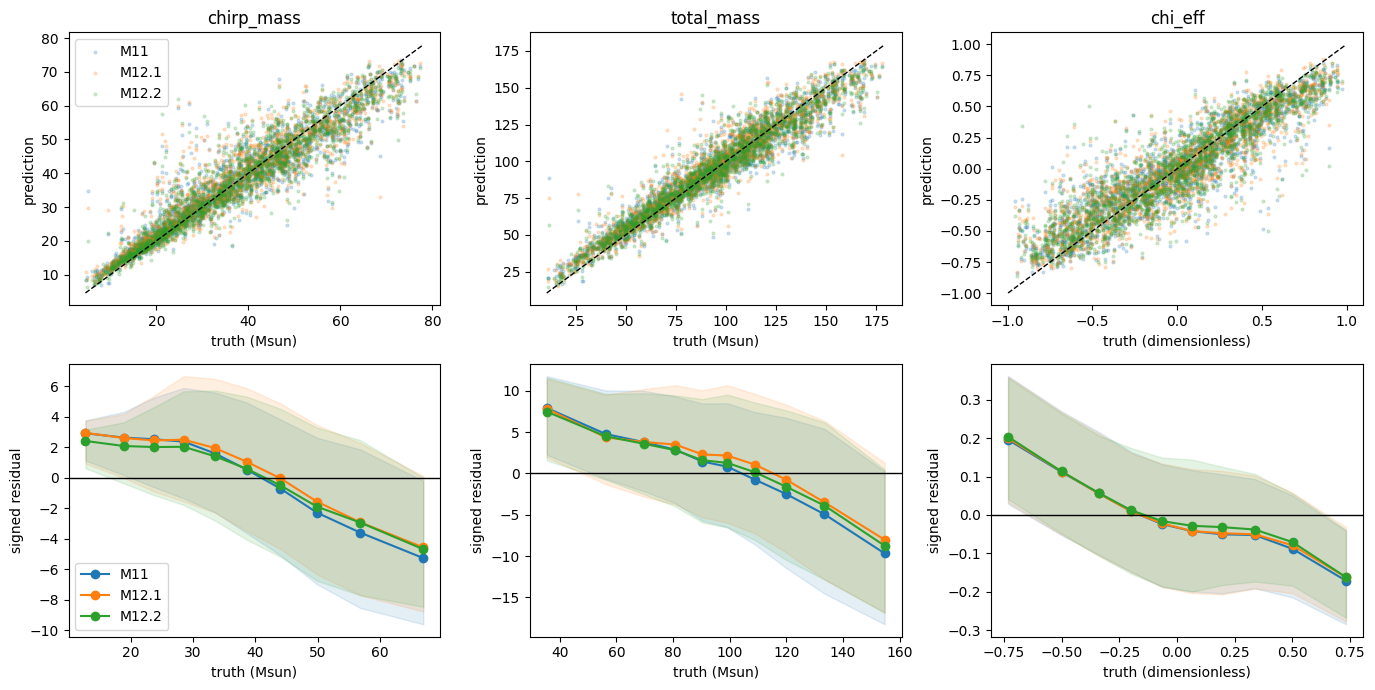

In [3]:
require((np.var(y_true, axis=0) > 0).all(), "OLS/R2 undefined for constant labels")
global_rows = []
for model, pred in predictions.items():
    table = regression_metrics(y_true, pred, LABELS, split_name="val").set_index("label")
    for j,label in enumerate(LABELS):
        slope, intercept = np.polyfit(y_true[:,j], pred[:,j], 1)
        global_rows.append(dict(model=model, label=label, unit=UNITS[j], n=len(val_ids),
            **table.loc[label, ["RMSE","MAE","R2","bias"]].to_dict(),
            slope=slope, intercept=intercept, slope_distance=abs(slope-1)))
global_metrics = pd.DataFrame(global_rows)
global_by_model = {m:global_metrics[global_metrics.model.eq(m)].set_index("label").reindex(LABELS)
                   for m in MODELS}
delta_tables = []
metrics = ["RMSE","MAE","R2","bias","slope","intercept","slope_distance"]
for ref in REFERENCES:
    base = global_by_model[ref]
    delta = global_by_model["M12.2"][metrics]-base[metrics]
    delta.columns = ["delta_"+c for c in delta.columns]
    delta["relative_RMSE_change"] = np.where(base.RMSE > 0,delta.delta_RMSE/base.RMSE,np.nan)
    delta["comparison"] = "M12.2 minus "+ref
    delta["reference"] = ref
    delta_tables.append(delta.reset_index())
global_delta = pd.concat(delta_tables,ignore_index=True)
display(global_metrics)
display(global_delta)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
chosen = np.linspace(0, len(val_ids)-1, min(2000,len(val_ids)), dtype=int)
for j,label in enumerate(LABELS):
    lo = min(y_true[:,j].min(), *(p[:,j].min() for p in predictions.values()))
    hi = max(y_true[:,j].max(), *(p[:,j].max() for p in predictions.values()))
    axes[0,j].plot([lo,hi], [lo,hi], "k--", linewidth=1)
    edges = np.unique(np.quantile(y_true[:,j], np.linspace(0,1,11)))
    groups = np.searchsorted(edges[1:-1], y_true[:,j], side="right")
    for model in MODELS:
        axes[0,j].scatter(y_true[chosen,j], predictions[model][chosen,j], s=4, alpha=.2, label=model)
        centers, means, lower, upper = [], [], [], []
        for b in range(len(edges)-1):
            mask = groups == b
            if mask.sum() >= MIN_COUNT:
                r = residuals[model][mask,j]
                centers.append(y_true[mask,j].mean()); means.append(r.mean())
                lower.append(np.quantile(r,.16)); upper.append(np.quantile(r,.84))
        line, = axes[1,j].plot(centers,means,"o-",label=model)
        axes[1,j].fill_between(centers,lower,upper,color=line.get_color(),alpha=.12)
    axes[0,j].set(title=label, xlabel=f"truth ({UNITS[j]})", ylabel="prediction")
    axes[1,j].axhline(0,color="black",linewidth=1)
    axes[1,j].set(xlabel=f"truth ({UNITS[j]})", ylabel="signed residual")
axes[0,0].legend(); axes[1,0].legend()
fig.tight_layout(); plt.show()


## 3. Q10/Q90 tails

Thresholds are linear quantiles of validation truth only. Lower ≤Q10 and upper ≥Q90 include ties; all models share these masks. Report signed bias, absolute bias, MAE and counts separately for both tails, plus both candidate-reference deltas. Quantiles are evaluation subset definitions, never training statistics. Do not cancel opposite tail signs.


In [4]:
thresholds = np.quantile(y_true,[.1,.9],axis=0)
tail_masks = {"lower":y_true <= thresholds[0],"upper":y_true >= thresholds[1]}
tail_rows = []
for j,label in enumerate(LABELS):
    for t,tail in enumerate(("lower","upper")):
        mask = tail_masks[tail][:,j]
        for model in MODELS:
            r = residuals[model][mask,j]
            tail_rows.append(dict(model=model,label=label,tail=tail,threshold=thresholds[t,j],
                n=int(mask.sum()),bias=r.mean(),abs_bias=abs(r.mean()),MAE=np.abs(r).mean()))
tails = pd.DataFrame(tail_rows)
tail_delta_rows = []
for ref in REFERENCES:
    for label in LABELS:
        for tail in ("lower","upper"):
            subset = tails[tails["label"].eq(label) & tails["tail"].eq(tail)].set_index("model")
            tail_delta_rows.append(dict(comparison="M12.2 minus "+ref,reference=ref,label=label,tail=tail,
                n=int(subset.loc[ref,"n"]),
                delta_bias=subset.loc["M12.2","bias"]-subset.loc[ref,"bias"],
                delta_abs_bias=subset.loc["M12.2","abs_bias"]-subset.loc[ref,"abs_bias"],
                delta_MAE=subset.loc["M12.2","MAE"]-subset.loc[ref,"MAE"]))
tail_deltas = pd.DataFrame(tail_delta_rows)
display(tails)
display(tail_deltas)


,model,label,tail,threshold,n,bias,abs_bias,MAE
0,M11,chirp_mass,lower,16.351124,4000,2.922491,2.922491,2.965636
1,M12.1,chirp_mass,lower,16.351124,4000,2.948652,2.948652,2.991768
2,M12.2,chirp_mass,lower,16.351124,4000,2.419627,2.419627,2.502264
3,M11,chirp_mass,upper,61.013297,4000,-5.258440,5.258440,5.795812
4,M12.1,chirp_mass,upper,61.013297,4000,-4.556152,4.556152,5.208116
5,M12.2,chirp_mass,upper,61.013297,4000,-4.676870,4.676870,5.266705
6,M11,total_mass,lower,48.156340,4000,7.925503,7.925503,8.447998
7,M12.1,total_mass,lower,48.156340,4000,7.841341,7.841341,8.351668
8,M12.2,total_mass,lower,48.156340,4000,7.478821,7.478821,8.106777
9,M11,total_mass,upper,141.954028,4000,-9.679648,9.679648,11.072026


,comparison,reference,label,tail,n,delta_bias,delta_abs_bias,delta_MAE
0,M12.2 minus M11,M11,chirp_mass,lower,4000,-0.502864,-0.502864,-0.463371
1,M12.2 minus M11,M11,chirp_mass,upper,4000,0.581571,-0.581571,-0.529106
2,M12.2 minus M11,M11,total_mass,lower,4000,-0.446682,-0.446682,-0.341221
3,M12.2 minus M11,M11,total_mass,upper,4000,0.928430,-0.928430,-0.883763
4,M12.2 minus M11,M11,chi_eff,lower,4000,0.007757,0.007757,0.004965
5,M12.2 minus M11,M11,chi_eff,upper,4000,0.009079,-0.009079,-0.009398
6,M12.2 minus M12.1,M12.1,chirp_mass,lower,4000,-0.529024,-0.529024,-0.489504
7,M12.2 minus M12.1,M12.1,chirp_mass,upper,4000,-0.120718,0.120718,0.058590
8,M12.2 minus M12.1,M12.1,total_mass,lower,4000,-0.362520,-0.362520,-0.244891
9,M12.2 minus M12.1,M12.1,total_mass,upper,4000,-0.725203,0.725203,0.332588


## 4. Global train-only Mahalanobis
Use M12.0's frozen μ, population σ, sample covariance and standardized-coordinate precision. Recompute train distances only to reconstruct its empirical CDF, and require the same sorted-distance hash. No evaluation covariance or percentile reference is fitted. Verify train moments/covariance against the saved contract before use. A numerical-library/hash discrepancy is an unresolved provenance issue; do not silently refit or relax it after seeing candidate results.

P(d) = 100 × fraction of train distances ≤ d (`searchsorted(..., side='right')`). Bins remain [0,20), [20,40), [40,60), [60,80), [80,100]. P80–P100 is peripheral. Counts need not be equal on validation. Conditional errors for n<30 are undefined, with counts retained. This is label-space Mahalanobis, not latent distance or marginal distance.

In [5]:
mu = np.asarray(geometry["mean"],dtype=float)
sigma = np.asarray(geometry["std_ddof0"],dtype=float)
precision = np.asarray(geometry["precision"],dtype=float)
require(mu.shape == sigma.shape == (3,) and precision.shape == (3,3)
        and np.isfinite(mu).all() and np.isfinite(sigma).all()
        and (sigma > 0).all() and np.isfinite(precision).all(), "Invalid frozen geometry")
np.testing.assert_allclose(train_y.mean(axis=0), mu, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(train_y.std(axis=0), sigma, rtol=1e-12, atol=1e-12)
np.testing.assert_allclose(np.cov(train_y,rowvar=False,ddof=1), geometry["covariance_ddof1"], rtol=1e-12, atol=1e-12)
def distance(values):
    z = (values-mu)/sigma
    squared = np.einsum("ni,ij,nj->n",z,precision,z)
    require(np.isfinite(squared).all() and (squared >= -1e-10).all(), "Invalid distance")
    return np.sqrt(np.maximum(squared,0))
reference_distances = np.sort(distance(train_y))
require(array_hash(reference_distances) == geometry["reference_distance_sha256"], "Train reference hash mismatch")
mahal_pct = 100*np.searchsorted(reference_distances,distance(y_true),side="right")/len(train_y)
require(np.isfinite(mahal_pct).all() and ((mahal_pct >= 0) & (mahal_pct <= 100)).all(), "Invalid percentiles")

def bin_masks(values, edges):
    return [(values >= lo) & ((values <= hi) if b == len(edges)-2 else (values < hi))
            for b,(lo,hi) in enumerate(zip(edges[:-1],edges[1:]))]

def compare_mask(mask, j, min_count=MIN_COUNT):
    n = int(mask.sum())
    row = dict(n=n, supported=n >= min_count)
    for model, prefix in PREFIX.items():
        r = residuals[model][mask,j]
        row[prefix+"_RMSE"] = float(np.sqrt(np.mean(r*r))) if n >= min_count else np.nan
        row[prefix+"_MAE"] = float(np.mean(np.abs(r))) if n >= min_count else np.nan
    for ref in REFERENCES:
        prefix = PREFIX[ref]
        for metric in ("RMSE","MAE"):
            row["delta_"+metric+"_vs_"+prefix] = row["M12_2_"+metric]-row[prefix+"_"+metric]
        baseline_rmse = row[prefix+"_RMSE"]
        row["relative_RMSE_change_vs_"+prefix] = (row["delta_RMSE_vs_"+prefix]/baseline_rmse
                                                 if baseline_rmse > 0 else np.nan)
    return row

def conditional(values, edges, dimension):
    masks = bin_masks(values,edges)
    return pd.DataFrame([dict(dimension=dimension, bin=b, lower=edges[b], upper=edges[b+1],
        upper_inclusive=b == len(edges)-2, label=label, **compare_mask(mask,j))
        for b,mask in enumerate(masks) for j,label in enumerate(LABELS)])

mahal_masks = bin_masks(mahal_pct,P_EDGES)
require((np.sum(mahal_masks,axis=0) == 1).all(), "Each validation row needs exactly one distance bin")
mahal_table = conditional(mahal_pct,P_EDGES,"global_mahalanobis_percentile")
require((mahal_table.groupby("label").n.sum().reindex(LABELS) == len(val_ids)).all(), "Incomplete distance counts")
peripheral = mahal_table[mahal_table.lower.eq(80)].set_index("label").reindex(LABELS)
display(mahal_table)
# Check candidate marginal provenance using only the same physical train labels.
# This does not change weights or refit any model.
from src.models.sample_weighting import marginal_label_weights
reproduced_weights, _, reproduced = marginal_label_weights(train_y,alpha=.5)
saved_marginal = provenance["predictions"]["M12.2"]["saved"]["model_config"]["sample_weighting"]
for key in ("reference_distance_sha256","normalized_weight_sha256",
            "normalized_weight_sha256_per_label","label_names","n_train"):
    require(reproduced[key] == saved_marginal[key], f"M12.2 marginal provenance mismatch: {key}")
for key in ("mean","std_ddof0","raw_weight_mean"):
    np.testing.assert_allclose(reproduced[key],saved_marginal[key],rtol=1e-12,atol=1e-12)
del reproduced_weights, _


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,M12_1_RMSE,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1
0,global_mahalanobis_percentile,0,0.0,20.0,False,chirp_mass,8007,True,4.902952,3.623689,5.043911,3.769283,5.081744,3.731903,0.178793,0.108214,0.036466,0.037833,-0.037381,0.007501
1,global_mahalanobis_percentile,0,0.0,20.0,False,total_mass,8007,True,8.630829,6.346546,9.041258,6.743996,8.802220,6.501053,0.171391,0.154506,0.019858,-0.239038,-0.242943,-0.026439
2,global_mahalanobis_percentile,0,0.0,20.0,False,chi_eff,8007,True,0.157579,0.121417,0.158548,0.122858,0.160879,0.124403,0.003300,0.002986,0.020943,0.002331,0.001545,0.014704
3,global_mahalanobis_percentile,1,20.0,40.0,False,chirp_mass,7957,True,5.342037,3.842708,5.274875,3.805945,5.372674,3.805759,0.030638,-0.036949,0.005735,0.097799,-0.000186,0.018541
4,global_mahalanobis_percentile,1,20.0,40.0,False,total_mass,7957,True,9.298274,6.800690,9.255271,6.824646,9.325178,6.786824,0.026905,-0.013867,0.002894,0.069908,-0.037822,0.007553
5,global_mahalanobis_percentile,1,20.0,40.0,False,chi_eff,7957,True,0.167364,0.128352,0.169591,0.130354,0.169635,0.129156,0.002271,0.000804,0.013568,0.000044,-0.001198,0.000260
6,global_mahalanobis_percentile,2,40.0,60.0,False,chirp_mass,8045,True,5.453683,3.817659,5.316852,3.712046,5.375091,3.665591,-0.078591,-0.152068,-0.014411,0.058239,-0.046455,0.010954
7,global_mahalanobis_percentile,2,40.0,60.0,False,total_mass,8045,True,9.758866,7.126635,9.435087,6.875484,9.603529,6.963304,-0.155336,-0.163330,-0.015917,0.168443,0.087820,0.017853
8,global_mahalanobis_percentile,2,40.0,60.0,False,chi_eff,8045,True,0.180632,0.136712,0.181862,0.137059,0.181841,0.136331,0.001209,-0.000382,0.006693,-0.000021,-0.000729,-0.000117
9,global_mahalanobis_percentile,3,60.0,80.0,False,chirp_mass,7952,True,5.982311,3.973223,5.705259,3.829190,5.766833,3.711889,-0.215478,-0.261335,-0.036019,0.061574,-0.117302,0.010792


## 5. Network SNR
Use only the saved `final_network_snr`: synthetic optimal final network SNR, 30–512 Hz, with M12.0 edges [10,12.5,15,17.5,20,22.5,25]. No catalog, requested, or recomputed SNR substitution. Nominal bins are left inclusive and final upper inclusive. Explicit under/overflow rows ensure every validation row is accounted for; all remain in global metrics. Low SNR below denotes [10,12.5), with out-of-range values reported separately. Global differences are in section 2; this table exposes their SNR dependence.

In [6]:
snr_table = pd.DataFrame()
low_snr = pd.DataFrame()
if snr is None:
    print("UNRESOLVED SNR:", snr_issue)
else:
    snr_table = conditional(snr,SNR_EDGES,"final_network_snr")
    outside = pd.DataFrame([dict(dimension="final_network_snr",bin=name, label=label,
        **compare_mask(mask,j)) for name,mask in (("below_10",snr < 10),("above_25",snr > 25))
        for j,label in enumerate(LABELS)])
    snr_table = pd.concat([snr_table,outside],ignore_index=True)
    require((snr_table.groupby("label").n.sum().reindex(LABELS) == len(val_ids)).all(), "Incomplete SNR counts")
    low_snr = snr_table[snr_table.bin.eq(0)].set_index("label").reindex(LABELS)
    display(snr_table)

,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,M12_1_RMSE,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1
0,final_network_snr,0,10.0,12.5,False,chirp_mass,6757,True,7.949685,5.582626,7.873660,5.602394,7.872869,5.457069,-0.076816,-0.125557,-0.009663,-0.000791,-0.145325,-0.000100
1,final_network_snr,0,10.0,12.5,False,total_mass,6757,True,14.979980,10.979815,14.931857,11.052351,14.828075,10.906622,-0.151905,-0.073194,-0.010141,-0.103782,-0.145729,-0.006950
2,final_network_snr,0,10.0,12.5,False,chi_eff,6757,True,0.261345,0.203745,0.261414,0.204278,0.266337,0.205312,0.004993,0.001567,0.019103,0.004923,0.001035,0.018832
3,final_network_snr,1,12.5,15.0,False,chirp_mass,6711,True,6.848787,4.743865,6.785508,4.693186,6.801236,4.615529,-0.047551,-0.128336,-0.006943,0.015728,-0.077657,0.002318
4,final_network_snr,1,12.5,15.0,False,total_mass,6711,True,12.570757,8.978671,12.364729,8.964175,12.460412,8.909150,-0.110345,-0.069521,-0.008778,0.095683,-0.055025,0.007738
5,final_network_snr,1,12.5,15.0,False,chi_eff,6711,True,0.225583,0.171863,0.223445,0.171109,0.227415,0.173038,0.001832,0.001174,0.008119,0.003970,0.001929,0.017766
6,final_network_snr,2,15.0,17.5,False,chirp_mass,6636,True,5.742407,3.955851,5.713259,3.919308,5.742102,3.853474,-0.000305,-0.102377,-0.000053,0.028843,-0.065834,0.005048
7,final_network_snr,2,15.0,17.5,False,total_mass,6636,True,10.025744,7.459881,9.896062,7.364110,10.067483,7.369445,0.041739,-0.090436,0.004163,0.171421,0.005336,0.017322
8,final_network_snr,2,15.0,17.5,False,chi_eff,6636,True,0.192272,0.145999,0.192102,0.146443,0.192031,0.145831,-0.000241,-0.000168,-0.001254,-0.000071,-0.000612,-0.000370
9,final_network_snr,3,17.5,20.0,False,chirp_mass,6625,True,4.924411,3.425289,4.991703,3.455960,4.941112,3.340149,0.016701,-0.085140,0.003392,-0.050591,-0.115811,-0.010135


## 6. Exploratory marginal and cross-label diagnostics

Reuse |y_k−μ_train,k|/σ_train,k and the per-label right-side train empirical CDF, with unchanged [0,20,40,60,80,100] percentile edges. Absolute distances merge upper/lower extremes; section 3 retains their signs. No validation statistics fit a training reference. Show each label's error versus its own peripherality, and all cross-label relations, especially mass error versus chi_eff peripherality.

Retain at most two coarse mass-P80 × spin-P80 tables, only when all four cells have ≥100 rows. False means <P80, not central. Marginal/cross-label patterns are descriptive associations, not causal evidence of shared-task gradient conflict. These exploratory tables do not override primary acceptance or justify retroactive weight tuning.


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,...,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1,reference_label
0,chirp_mass,0,0.0,20.0,False,chirp_mass,7912,True,5.095718,3.642738,...,3.977972,5.522998,3.954151,0.427280,0.311413,0.083851,0.025502,-0.023821,0.004639,chirp_mass
3,chirp_mass,1,20.0,40.0,False,chirp_mass,7928,True,5.449723,3.830882,...,3.987652,5.671527,3.937110,0.221803,0.106228,0.040700,0.019058,-0.050542,0.003372,chirp_mass
6,chirp_mass,2,40.0,60.0,False,chirp_mass,8165,True,5.651507,3.863706,...,3.787221,5.639481,3.740484,-0.012025,-0.123222,-0.002128,-0.027466,-0.046737,-0.004847,chirp_mass
9,chirp_mass,3,60.0,80.0,False,chirp_mass,8074,True,5.849986,3.812921,...,3.678010,5.657031,3.465194,-0.192955,-0.347727,-0.032984,-0.117285,-0.212816,-0.020311,chirp_mass
12,chirp_mass,4,80.0,100.0,True,chirp_mass,7921,True,6.929244,4.602003,...,4.271071,6.458758,4.100808,-0.470486,-0.501195,-0.067899,0.098165,-0.170263,0.015433,chirp_mass
16,total_mass,0,0.0,20.0,False,total_mass,7969,True,9.160533,6.511800,...,7.201736,9.834819,6.923235,0.674285,0.411435,0.073608,-0.180139,-0.278501,-0.017987,total_mass
19,total_mass,1,20.0,40.0,False,total_mass,7961,True,9.253008,6.633318,...,7.094675,9.400186,6.779210,0.147178,0.145893,0.015906,-0.304758,-0.315464,-0.031402,total_mass
22,total_mass,2,40.0,60.0,False,total_mass,8004,True,9.517805,7.085091,...,7.005247,9.522222,7.001933,0.004417,-0.083158,0.000464,0.056925,-0.003315,0.006014,total_mass
25,total_mass,3,60.0,80.0,False,total_mass,8127,True,10.383890,7.722701,...,7.248703,10.061718,7.383199,-0.322172,-0.339501,-0.031026,0.216046,0.134497,0.021943,total_mass
28,total_mass,4,80.0,100.0,True,total_mass,7939,True,13.930931,9.771142,...,9.116091,13.253215,9.155092,-0.677717,-0.616050,-0.048648,0.223216,0.039001,0.017131,total_mass


,dimension,bin,lower,upper,upper_inclusive,label,n,supported,M11_RMSE,M11_MAE,...,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1,reference_label
1,chirp_mass,0,0.0,20.0,False,total_mass,7912,True,8.487750,6.188167,...,6.844129,9.002682,6.553980,0.514932,0.365813,0.060668,-0.258499,-0.290149,-0.027912,chirp_mass
2,chirp_mass,0,0.0,20.0,False,chi_eff,7912,True,0.170752,0.130116,...,0.132861,0.176646,0.134603,0.005894,0.004487,0.034516,0.002538,0.001743,0.014580,chirp_mass
4,chirp_mass,1,20.0,40.0,False,total_mass,7928,True,9.033148,6.581467,...,6.920786,9.289376,6.733830,0.256228,0.152363,0.028365,-0.133809,-0.186956,-0.014200,chirp_mass
5,chirp_mass,1,20.0,40.0,False,chi_eff,7928,True,0.172705,0.132812,...,0.134246,0.176653,0.135650,0.003948,0.002838,0.022859,0.001898,0.001405,0.010863,chirp_mass
7,chirp_mass,2,40.0,60.0,False,total_mass,8165,True,9.767927,7.239747,...,7.046129,9.702155,7.085969,-0.065772,-0.153779,-0.006733,0.009367,0.039840,0.000966,chirp_mass
8,chirp_mass,2,40.0,60.0,False,chi_eff,8165,True,0.183597,0.138740,...,0.138784,0.184591,0.138129,0.000994,-0.000611,0.005413,0.001485,-0.000654,0.008112,chirp_mass
10,chirp_mass,3,60.0,80.0,False,total_mass,8074,True,10.587431,7.848113,...,7.600728,10.414075,7.583305,-0.173356,-0.264808,-0.016374,0.105135,-0.017423,0.010198,chirp_mass
11,chirp_mass,3,60.0,80.0,False,chi_eff,8074,True,0.197078,0.147099,...,0.145316,0.193247,0.143298,-0.003830,-0.003801,-0.019436,-0.001452,-0.002018,-0.007457,chirp_mass
13,chirp_mass,4,80.0,100.0,True,total_mass,7921,True,14.174385,9.863410,...,9.254580,13.518728,9.284701,-0.655657,-0.578709,-0.046256,0.251993,0.030121,0.018994,chirp_mass
14,chirp_mass,4,80.0,100.0,True,chi_eff,7921,True,0.239565,0.177786,...,0.177724,0.240708,0.175475,0.001143,-0.002311,0.004773,0.003373,-0.002249,0.014214,chirp_mass


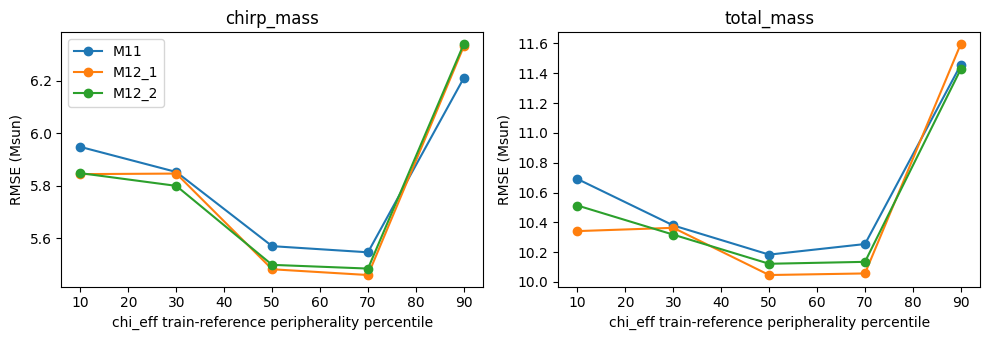

,label,mass_P80,chi_eff_P80,n
0,chirp_mass,False,False,25682
1,chirp_mass,False,True,6397
2,chirp_mass,True,False,6480
3,chirp_mass,True,True,1441
4,total_mass,False,False,25594
5,total_mass,False,True,6467
6,total_mass,True,False,6568
7,total_mass,True,True,1371


,label,mass_P80,chi_eff_P80,n,supported,M11_RMSE,M11_MAE,M12_1_RMSE,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1
0,chirp_mass,False,False,25682,True,5.387912,3.739828,5.487843,3.784182,5.440073,3.689299,0.052161,-0.050529,0.009681,-0.047770,-0.094882,-0.008705
1,chirp_mass,False,True,6397,True,6.028209,3.982961,6.256405,4.145909,6.305941,4.106471,0.277732,0.123510,0.046072,0.049536,-0.039438,0.007918
2,chirp_mass,True,False,6480,True,6.921231,4.638316,6.292859,4.288417,6.450719,4.150802,-0.470512,-0.487513,-0.067981,0.157860,-0.137614,0.025086
3,chirp_mass,True,True,1441,True,6.965160,4.438711,6.656671,4.193070,6.494783,3.875991,-0.470377,-0.562720,-0.067533,-0.161887,-0.317079,-0.024320
4,total_mass,False,False,25594,True,9.267604,6.763812,9.380108,6.868207,9.350966,6.789990,0.083363,0.026177,0.008995,-0.029142,-0.078217,-0.003107
5,total_mass,False,True,6467,True,10.793940,7.895286,11.136705,8.205761,11.016144,7.948707,0.222205,0.053421,0.020586,-0.120561,-0.257054,-0.010826
6,total_mass,True,False,6568,True,13.879541,9.705829,12.916832,9.041333,13.264245,9.116128,-0.615296,-0.589701,-0.044331,0.347413,0.074795,0.026896
7,total_mass,True,True,1371,True,14.174539,10.084035,13.559051,9.474232,13.200244,9.341755,-0.974296,-0.742281,-0.068736,-0.358807,-0.132477,-0.026463


In [7]:
marginal_pct = np.empty_like(y_true)
marginal_reference_hashes = {}
for j,label in enumerate(LABELS):
    reference = np.sort(np.abs((train_y[:,j]-mu[j])/sigma[j]))
    query = np.abs((y_true[:,j]-mu[j])/sigma[j])
    marginal_pct[:,j] = 100*np.searchsorted(reference,query,side="right")/len(reference)
    marginal_reference_hashes[label] = array_hash(reference)
    require(marginal_reference_hashes[label] == saved_marginal["reference_distance_sha256"][label],
            f"Marginal diagnostic reference mismatch: {label}")
require(np.isfinite(marginal_pct).all() and ((marginal_pct >= 0) & (marginal_pct <= 100)).all(), "Marginal percentile bounds")
for j in range(3):
    require((np.sum(bin_masks(marginal_pct[:,j],P_EDGES),axis=0) == 1).all(), "Marginal bin assignment")
marginal_table = pd.concat([conditional(marginal_pct[:,j],P_EDGES,label).assign(reference_label=label)
                           for j,label in enumerate(LABELS)],ignore_index=True)
require((marginal_table.groupby(["reference_label","label"]).n.sum() == len(val_ids)).all(), "Marginal counts")
own_periphery = marginal_table[marginal_table.reference_label.eq(marginal_table.label)]
cross_label = marginal_table[~marginal_table.reference_label.eq(marginal_table.label)]
display(own_periphery)
display(cross_label)
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
for ax,label in zip(axes,LABELS[:2]):
    sub = marginal_table[marginal_table.reference_label.eq("chi_eff") & marginal_table.label.eq(label)]
    for prefix in PREFIX.values():
        ax.plot((sub.lower+sub.upper)/2,sub[prefix+"_RMSE"],"o-",label=prefix)
    ax.set(title=label, xlabel="chi_eff train-reference peripherality percentile", ylabel="RMSE (Msun)")
axes[0].legend(); fig.tight_layout(); plt.show()

summaries_2d, support_2d = [], []
for j,label in enumerate(LABELS[:2]):
    masks = [(a,b, ((marginal_pct[:,j] >= 80) == a) & ((marginal_pct[:,2] >= 80) == b))
             for a in (False,True) for b in (False,True)]
    support_2d.extend(dict(label=label, mass_P80=a, chi_eff_P80=b, n=int(mask.sum())) for a,b,mask in masks)
    if all(mask.sum() >= MIN_2D_COUNT for _,_,mask in masks):
        summaries_2d.extend(dict(label=label, mass_P80=a, chi_eff_P80=b,
            **compare_mask(mask,j,MIN_2D_COUNT)) for a,b,mask in masks)
    else:
        print("2D error summary skipped for inadequate support:",label)
display(pd.DataFrame(support_2d))
if summaries_2d:
    display(pd.DataFrame(summaries_2d))
provenance["marginal_reference_hashes"] = marginal_reference_hashes
del train_y, reference_distances, reference  # no later cells need train-label arrays

### 6b. Discordant mass/spin regions — exploratory

Reuse the diagnostic notebook's fixed train-reference definitions: peripheral ≥P80, central ≤P50. For chirp_mass and total_mass separately, compare mass peripheral/spin central and mass central/spin peripheral. The middle band is excluded only from these contrasts; regions can overlap across masses and must not be summed. Show counts, all three target errors and both candidate-reference deltas. Suppress errors for n<100. Regions are determined by truth coordinates, never by a model's predictions. No new figures or outcome-driven thresholds.


In [8]:
discordant_rows = []
for j,mass_label in enumerate(LABELS[:2]):
    regions = {
        "mass_peripheral_spin_central":(marginal_pct[:,j] >= 80) & (marginal_pct[:,2] <= 50),
        "mass_central_spin_peripheral":(marginal_pct[:,j] <= 50) & (marginal_pct[:,2] >= 80)}
    for region,mask in regions.items():
        for k,label in enumerate(LABELS):
            discordant_rows.append(dict(mass_definition=mass_label,region=region,label=label,
                fraction=float(mask.mean()),**compare_mask(mask,k,MIN_2D_COUNT)))
discordant = pd.DataFrame(discordant_rows)
display(discordant)


,mass_definition,region,label,fraction,n,supported,M11_RMSE,M11_MAE,M12_1_RMSE,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1
0,chirp_mass,mass_peripheral_spin_central,chirp_mass,0.102275,4091,True,7.110841,4.779011,6.513362,4.455414,6.589666,4.301862,-0.521175,-0.477150,-0.073293,0.076304,-0.153552,0.011715
1,chirp_mass,mass_peripheral_spin_central,total_mass,0.102275,4091,True,14.468724,9.975431,13.423655,9.330045,13.722446,9.393397,-0.746277,-0.582035,-0.051579,0.298791,0.063352,0.022259
2,chirp_mass,mass_peripheral_spin_central,chi_eff,0.102275,4091,True,0.204748,0.155787,0.207274,0.159148,0.215368,0.163949,0.010621,0.008162,0.051872,0.008094,0.004801,0.039052
3,chirp_mass,mass_central_spin_peripheral,chirp_mass,0.095150,3806,True,5.649052,3.898724,5.831289,4.083248,6.083877,4.210574,0.434825,0.311850,0.076973,0.252587,0.127326,0.043316
4,chirp_mass,mass_central_spin_peripheral,total_mass,0.095150,3806,True,9.611881,6.973562,9.996359,7.367205,9.950074,7.167788,0.338192,0.194225,0.035185,-0.046286,-0.199418,-0.004630
5,chirp_mass,mass_central_spin_peripheral,chi_eff,0.095150,3806,True,0.220541,0.172799,0.225012,0.177133,0.229990,0.180612,0.009450,0.007812,0.042848,0.004978,0.003478,0.022125
6,total_mass,mass_peripheral_spin_central,chirp_mass,0.104400,4176,True,6.642623,4.300453,6.137374,4.046137,6.159258,3.855257,-0.483365,-0.445196,-0.072767,0.021884,-0.190880,0.003566
7,total_mass,mass_peripheral_spin_central,total_mass,0.104400,4176,True,14.183289,9.853808,13.337824,9.292277,13.538556,9.327711,-0.644733,-0.526097,-0.045457,0.200732,0.035434,0.015050
8,total_mass,mass_peripheral_spin_central,chi_eff,0.104400,4176,True,0.202383,0.153989,0.204792,0.156880,0.214440,0.163604,0.012056,0.009615,0.059571,0.009648,0.006725,0.047109
9,total_mass,mass_central_spin_peripheral,chirp_mass,0.104250,4170,True,6.406320,4.242515,6.810728,4.526904,6.893896,4.536645,0.487577,0.294130,0.076109,0.083168,0.009741,0.012211


## 7. Paired bootstrap — explicit manual opt-in

Default 400 replicates, seed 123, RUN_BOOTSTRAP=False. Each replicate draws validation positions once, uses the identical original row IDs for all three models, and returns both M12.2−M11 and M12.2−M12.1 deltas. One replicate's sampled arrays are held at a time; no B×N prediction array.

Retain RMSE, slope distance |slope−1| and absolute lower/upper tail bias intervals. Also report peripheral P80–P100 RMSE and low-SNR [10,12.5) RMSE intervals for the primary safeguards. Freeze quantile thresholds, marginal/global reference mappings and subset masks before resampling. Unsupported subsets produce NaN; valid/invalid replicate counts are explicit. Central 95% percentile intervals are marginal and unadjusted for multiple comparisons.

These intervals are conditional on the trained, validation-selected checkpoints and fixed thresholds. They exclude seed variation and assume independent rows. Source grouping beyond original HDF5 row IDs is unresolved; do not claim source-independent uncertainty. Nothing is computed until this cell is explicitly run with the flag enabled.


In [9]:
bootstrap_summary = pd.DataFrame()
bootstrap_deltas = None
bootstrap_metrics = ["RMSE","slope_distance","lower_abs_bias","upper_abs_bias",
                     "peripheral_RMSE","low_SNR_RMSE"]

def bootstrap_statistics(positions):
    truth = y_true[positions]
    centered = truth-truth.mean(axis=0)
    ss = np.sum(centered*centered,axis=0)
    stats = {}
    for model in MODELS:
        pred = predictions[model][positions]
        r = pred-truth
        rmse = np.sqrt(np.mean(r*r,axis=0))
        slope = np.divide(np.sum(centered*pred,axis=0),ss,out=np.full(3,np.nan),where=ss > 0)
        tail_bias = []
        for tail in ("lower","upper"):
            mask = tail_masks[tail][positions]
            counts = mask.sum(axis=0)
            bias = np.divide(np.sum(r*mask,axis=0),counts,out=np.full(3,np.nan),where=counts > 0)
            tail_bias.append(np.abs(bias))
        conditional_rmse = []
        masks = [mahal_pct[positions] >= 80,
                 ((snr[positions] >= 10) & (snr[positions] < 12.5)) if snr is not None
                 else np.zeros(len(positions),dtype=bool)]
        for mask in masks:
            conditional_rmse.append(np.sqrt(np.mean(r[mask]**2,axis=0)) if mask.sum() >= MIN_COUNT
                                    else np.full(3,np.nan))
        stats[model] = np.column_stack([rmse,abs(slope-1),*tail_bias,*conditional_rmse])
    return np.stack([stats["M12.2"]-stats[ref] for ref in REFERENCES])

if RUN_BOOTSTRAP:
    require(isinstance(BOOTSTRAP_COUNT,int) and BOOTSTRAP_COUNT >= 100,"Use >=100 replicates; default 400")
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    bootstrap_deltas = np.empty((BOOTSTRAP_COUNT,len(REFERENCES),3,len(bootstrap_metrics)),dtype=float)
    for b in range(BOOTSTRAP_COUNT):
        positions = rng.integers(0,len(val_ids),size=len(val_ids))
        bootstrap_deltas[b] = bootstrap_statistics(positions)
    points = bootstrap_statistics(np.arange(len(val_ids)))
    rows = []
    for a,ref in enumerate(REFERENCES):
        for j,label in enumerate(LABELS):
            for k,metric in enumerate(bootstrap_metrics):
                samples = bootstrap_deltas[:,a,j,k]
                valid = samples[np.isfinite(samples)]
                sufficient = len(valid) >= max(100,int(np.ceil(.95*BOOTSTRAP_COUNT)))
                lo,hi = np.quantile(valid,[.025,.975]) if sufficient else (np.nan,np.nan)
                rows.append(dict(comparison="M12.2 minus "+ref,reference=ref,label=label,metric=metric,
                    delta=points[a,j,k],ci_low=lo,ci_high=hi,n_valid=len(valid),
                    n_invalid=BOOTSTRAP_COUNT-len(valid),seed=BOOTSTRAP_SEED,supported=sufficient))
    bootstrap_summary = pd.DataFrame(rows)
    display(bootstrap_summary)
else:
    print("Bootstrap skipped. Explicitly enable RUN_BOOTSTRAP and run this cell when ready.")


,comparison,reference,label,metric,delta,ci_low,ci_high,n_valid,n_invalid,seed,supported
0,M12.2 minus M11,M11,chirp_mass,RMSE,-0.028976,-0.077814,0.017268,400,0,123,True
1,M12.2 minus M11,M11,chirp_mass,slope_distance,-0.025661,-0.027098,-0.024348,400,0,123,True
2,M12.2 minus M11,M11,chirp_mass,lower_abs_bias,-0.502864,-0.562502,-0.434752,400,0,123,True
3,M12.2 minus M11,M11,chirp_mass,upper_abs_bias,-0.581571,-0.671562,-0.509276,400,0,123,True
4,M12.2 minus M11,M11,chirp_mass,peripheral_RMSE,-0.029515,-0.171558,0.111780,400,0,123,True
5,M12.2 minus M11,M11,chirp_mass,low_SNR_RMSE,-0.076816,-0.216034,0.048021,400,0,123,True
6,M12.2 minus M11,M11,total_mass,RMSE,-0.089068,-0.193918,0.004324,400,0,123,True
7,M12.2 minus M11,M11,total_mass,slope_distance,-0.014629,-0.016058,-0.013307,400,0,123,True
8,M12.2 minus M11,M11,total_mass,lower_abs_bias,-0.446682,-0.591441,-0.275954,400,0,123,True
9,M12.2 minus M11,M11,total_mass,upper_abs_bias,-0.928430,-1.079189,-0.788985,400,0,123,True


## 8. Primary provisional acceptance versus M11; incremental comparison versus M12.1

Primary: ≤2% global RMSE degradation per label versus M11; both mass slopes closer to one; reduced absolute Q10 and Q90 signed bias for both masses. Retain the existing extreme-global-periphery definition P80–P100: at least one mass RMSE improves with no material deterioration in the other. The current M12.1 notebook sets the peripheral-mass tolerance to 2%; retain it explicitly as provisional. The same descriptive deltas versus M12.1 are reported, without treating M12.1 as a replacement for M11 guardrails.

No material chi_eff or low-SNR regressions: display their global/tail/peripheral and low-SNR errors separately. A 2% global chi_eff guardrail does not settle every chi_eff failure mode. Separate conditional chi_eff and low-SNR RMSE tolerances remain configurable/unset until prospectively decided; unset is unresolved, never pass. Review SNR under/overflow and tail MAE too. No arbitrary aggregate score or automatic overall acceptance.

Point-direction checks and bootstrap intervals are separate: a point improvement with an interval crossing zero is uncertain. Exploratory marginal/cross-label/discordant findings cannot rescue failed primary criteria. Validation already selected checkpoints and is not an untouched final generalization test. No test or real-event evaluation is performed here.


In [10]:
def interval_for(ref,label,metric):
    if bootstrap_summary.empty:
        return dict(ci_low=np.nan,ci_high=np.nan,uncertainty="not computed")
    row = bootstrap_summary[(bootstrap_summary.reference == ref) &
        (bootstrap_summary.label == label) & (bootstrap_summary.metric == metric)].iloc[0]
    return dict(ci_low=row.ci_low,ci_high=row.ci_high,
        uncertainty="negative delta supported" if row.ci_high < 0 else
        "nonnegative delta supported" if row.ci_low >= 0 else "inconclusive/undefined")

acceptance_rows = []
for ref in REFERENCES:
    gd = global_delta[global_delta.reference.eq(ref)].set_index("label")
    for label in LABELS:
        rel = gd.loc[label,"relative_RMSE_change"]
        status = ("within provisional 2%" if rel <= .02 else "exceeds provisional 2%") if np.isfinite(rel) else "undefined"
        acceptance_rows.append(dict(reference=ref,label=label,criterion="global RMSE",
            role="primary guardrail" if ref == "M11" else "incremental comparison only",
            delta=gd.loc[label,"delta_RMSE"],relative_change=rel,
            point_status=status if ref == "M11" else "inspect incremental change",
            **interval_for(ref,label,"RMSE")))
        for metric in ("slope_distance","lower_abs_bias","upper_abs_bias"):
            if metric == "slope_distance":
                delta = gd.loc[label,"delta_slope_distance"]
            else:
                tail = metric.split("_")[0]
                # Explicit label AND tail AND reference; never select a different mass's tail.
                delta = tail_deltas.loc[tail_deltas["reference"].eq(ref) &
                    tail_deltas["label"].eq(label) & tail_deltas["tail"].eq(tail),"delta_abs_bias"].iloc[0]
            acceptance_rows.append(dict(reference=ref,label=label,criterion=metric,delta=delta,
                role="primary mass criterion" if ref == "M11" and label in LABELS[:2] else "separate diagnostic",
                point_status="improved" if delta < 0 else "not improved",**interval_for(ref,label,metric)))
acceptance_table = pd.DataFrame(acceptance_rows)
display(acceptance_table)
display(peripheral)
peripheral_status = []
for ref in REFERENCES:
    suffix = PREFIX[ref]
    masses = peripheral.loc[LABELS[:2]]
    changes = masses["relative_RMSE_change_vs_"+suffix]
    if not masses.supported.all() or not np.isfinite(changes).all():
        status = "unresolved support"
    elif PERIPHERAL_MASS_MAX_DEGRADATION is None:
        status = "unresolved material-deterioration tolerance"
    else:
        require(np.isfinite(PERIPHERAL_MASS_MAX_DEGRADATION) and PERIPHERAL_MASS_MAX_DEGRADATION >= 0,
                "Invalid peripheral tolerance")
        ok = ((masses["delta_RMSE_vs_"+suffix] < 0).any() &
              (changes <= PERIPHERAL_MASS_MAX_DEGRADATION).all())
        status = "point criterion met" if ok else "point criterion not met"
    peripheral_status.append(dict(reference=ref,status=status,
        role="primary" if ref == "M11" else "incremental only"))
display(pd.DataFrame(peripheral_status))

def safeguard_status(change,tolerance):
    if not np.isfinite(change):
        return "unresolved support/reference RMSE"
    if tolerance is None:
        return "unresolved material-deterioration tolerance"
    require(np.isfinite(tolerance) and tolerance >= 0,"Invalid safeguard tolerance")
    return "within provisional tolerance" if change <= tolerance else "exceeds provisional tolerance"

safeguards = []
for ref in REFERENCES:
    suffix = PREFIX[ref]
    # chi_eff global and peripheral safeguards; its two tails are separately displayed above.
    gd = global_delta[global_delta.reference.eq(ref)].set_index("label")
    for scope,change in (("chi_eff global",gd.loc["chi_eff","relative_RMSE_change"]),
                        ("chi_eff peripheral",peripheral.loc["chi_eff","relative_RMSE_change_vs_"+suffix])):
        safeguards.append(dict(reference=ref,scope=scope,relative_RMSE_change=change,
            status=safeguard_status(change,CHI_EFF_MAX_DEGRADATION)))
    for label in LABELS:
        change = low_snr.loc[label,"relative_RMSE_change_vs_"+suffix] if not low_snr.empty else np.nan
        safeguards.append(dict(reference=ref,scope="low SNR "+label,relative_RMSE_change=change,
            status=safeguard_status(change,LOW_SNR_MAX_DEGRADATION)))
display(pd.DataFrame(safeguards))
if not low_snr.empty:
    display(low_snr)
else:
    print("Low-SNR assessment unresolved:",snr_issue)
evaluation_summary = dict(split="val",provenance=provenance,
    global_metrics=global_metrics.to_dict("records"),global_deltas=global_delta.to_dict("records"),
    tails=tails.to_dict("records"),tail_deltas=tail_deltas.to_dict("records"),
    acceptance=acceptance_table.to_dict("records"),peripheral_status=peripheral_status,
    safeguards=safeguards,bootstrap=bootstrap_summary.to_dict("records"),overall_decision=None)
print("No overall acceptance score or final scientific conclusion is generated.")


,reference,label,criterion,role,delta,relative_change,point_status,ci_low,ci_high,uncertainty
0,M11,chirp_mass,global RMSE,primary guardrail,-0.028976,-0.004972,within provisional 2%,-0.077814,0.017268,inconclusive/undefined
1,M11,chirp_mass,slope_distance,primary mass criterion,-0.025661,NaN,improved,-0.027098,-0.024348,negative delta supported
2,M11,chirp_mass,lower_abs_bias,primary mass criterion,-0.502864,NaN,improved,-0.562502,-0.434752,negative delta supported
3,M11,chirp_mass,upper_abs_bias,primary mass criterion,-0.581571,NaN,improved,-0.671562,-0.509276,negative delta supported
4,M11,total_mass,global RMSE,primary guardrail,-0.089068,-0.008405,within provisional 2%,-0.193918,0.004324,inconclusive/undefined
5,M11,total_mass,slope_distance,primary mass criterion,-0.014629,NaN,improved,-0.016058,-0.013307,negative delta supported
6,M11,total_mass,lower_abs_bias,primary mass criterion,-0.446682,NaN,improved,-0.591441,-0.275954,negative delta supported
7,M11,total_mass,upper_abs_bias,primary mass criterion,-0.928430,NaN,improved,-1.079189,-0.788985,negative delta supported
8,M11,chi_eff,global RMSE,primary guardrail,0.001436,0.007387,within provisional 2%,0.000257,0.002536,nonnegative delta supported
9,M11,chi_eff,slope_distance,separate diagnostic,-0.008718,NaN,improved,-0.010550,-0.006943,negative delta supported


,dimension,bin,lower,upper,upper_inclusive,n,supported,M11_RMSE,M11_MAE,M12_1_RMSE,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1
label,,,,,,,,,,,,,,,,,,,
chirp_mass,global_mahalanobis_percentile,4,80.0,100.0,True,8039,True,7.184116,4.487907,7.338602,4.572734,7.154602,4.270406,-0.029515,-0.217501,-0.004108,-0.184000,-0.302328,-0.025073
total_mass,global_mahalanobis_percentile,4,80.0,100.0,True,8039,True,13.378729,9.439477,13.376794,9.488765,13.341168,9.297465,-0.037561,-0.142012,-0.002808,-0.035625,-0.191299,-0.002663
chi_eff,global_mahalanobis_percentile,4,80.0,100.0,True,8039,True,0.246372,0.183222,0.244473,0.183493,0.248725,0.182897,0.002353,-0.000324,0.009549,0.004252,-0.000595,0.017393


,reference,status,role
0,M11,point criterion met,primary
1,M12.1,point criterion met,incremental only


,reference,scope,relative_RMSE_change,status
0,M11,chi_eff global,0.007387,unresolved material-deterioration tolerance
1,M11,chi_eff peripheral,0.009549,unresolved material-deterioration tolerance
2,M11,low SNR chirp_mass,-0.009663,unresolved material-deterioration tolerance
3,M11,low SNR total_mass,-0.010141,unresolved material-deterioration tolerance
4,M11,low SNR chi_eff,0.019103,unresolved material-deterioration tolerance
5,M12.1,chi_eff global,0.008262,unresolved material-deterioration tolerance
6,M12.1,chi_eff peripheral,0.017393,unresolved material-deterioration tolerance
7,M12.1,low SNR chirp_mass,-0.000100,unresolved material-deterioration tolerance
8,M12.1,low SNR total_mass,-0.006950,unresolved material-deterioration tolerance
9,M12.1,low SNR chi_eff,0.018832,unresolved material-deterioration tolerance


,dimension,bin,lower,upper,upper_inclusive,n,supported,M11_RMSE,M11_MAE,M12_1_RMSE,M12_1_MAE,M12_2_RMSE,M12_2_MAE,delta_RMSE_vs_M11,delta_MAE_vs_M11,relative_RMSE_change_vs_M11,delta_RMSE_vs_M12_1,delta_MAE_vs_M12_1,relative_RMSE_change_vs_M12_1
label,,,,,,,,,,,,,,,,,,,
chirp_mass,final_network_snr,0,10.0,12.5,False,6757,True,7.949685,5.582626,7.873660,5.602394,7.872869,5.457069,-0.076816,-0.125557,-0.009663,-0.000791,-0.145325,-0.000100
total_mass,final_network_snr,0,10.0,12.5,False,6757,True,14.979980,10.979815,14.931857,11.052351,14.828075,10.906622,-0.151905,-0.073194,-0.010141,-0.103782,-0.145729,-0.006950
chi_eff,final_network_snr,0,10.0,12.5,False,6757,True,0.261345,0.203745,0.261414,0.204278,0.266337,0.205312,0.004993,0.001567,0.019103,0.004923,0.001035,0.018832


No overall acceptance score or final scientific conclusion is generated.


## Manual execution and compatibility limitations

1. Use the existing project Python 3.10 environment and DATA_ROOT convention. Review the recorded M11/M12.1 archive paths and set M12_2_VALIDATION_PATH only after the completed validation predictions have been saved. No inference is triggered here.
2. Run section 1 and stop on any mismatch. Run sections 2–6b in order. Do not Run All.
3. Optionally set RUN_BOOTSTRAP=True with the seed/count chosen prospectively, execute section 7, then section 8. Without bootstrap, uncertainty remains explicitly uncomputed.

M12.2 archives must retain model_config.sample_weighting, including per-label reference hashes, per-label and full normalized-weight hashes, mean/std, raw normalization means, train-ID hash, label order and the unweighted-validation objective. Metadata-stripped or older schemas are incompatible: obtain verified provenance separately rather than infer it from predictions. No checkpoint deserialization or independent checkpoint-byte verification is performed. Cross-platform reference-hash mismatches require investigation, not automatic relaxation.

The current running checkpoint, future prediction file, runtime alignment and numerical results remain unverified. Source-level dependence beyond row IDs and material chi_eff/low-SNR tolerances remain unresolved. The older M12.1 notebook contained a tail-selection expression that did not filter by label; this adaptation explicitly filters by label, tail and reference, without modifying that historical notebook.

No outputs, conclusions, tests, training, inference or benchmarks were executed during creation. No existing file is changed.


## 9. Scientific conclusions and decision — M12.2 marginal weighted MSE

### 9.1. Experimental objective

M12.2 investigated whether replacing the shared, global Mahalanobis-based sample weights of M12.1 with independent parameter-specific marginal weights could improve the regression trade-off, especially in regions where mass and effective-spin peripherality disagree.

The intervention modified only the training loss. The frozen G1 dataset and splits, architecture, input normalization, target standardization, optimizer, seed, training configuration, and unweighted validation-based checkpoint selection were preserved.

All comparisons were performed on the same 40,000 validation examples, with verified sample-ID alignment. Paired percentile bootstrap intervals were estimated from 400 resamples.

### 9.2. Global predictive performance

M12.2 achieved validation RMSE values of:

| Parameter | M11 | M12.1 | M12.2 |
|---|---:|---:|---:|
| Chirp mass ($M_\odot$) | 5.8274 | 5.7972 | 5.7984 |
| Total mass ($M_\odot$) | 10.5977 | 10.4903 | 10.5086 |
| Effective spin | 0.19433 | 0.19416 | 0.19577 |

Relative to M11, M12.2 reduced chirp-mass RMSE by approximately 0.50% and total-mass RMSE by 0.84%, while increasing effective-spin RMSE by 0.74%. All three global RMSE changes remained within the provisional 2% degradation guardrail.

Compared with M12.1, global mass-RMSE differences were small and their paired-bootstrap 95% intervals included zero. In contrast, the effective-spin RMSE deterioration was supported by its paired-bootstrap interval.

M12.2 achieved the lowest mass MAE among the three models (3.8375 and 7.4467 solar masses for chirp mass and total mass, respectively), suggesting an improvement in average absolute errors that is not equally reflected in the RMSE.

### 9.3. Regression-to-the-mean and tail biases

M12.2 improved the chirp-mass prediction slope from 0.8351 (M11) and 0.8522 (M12.1) to 0.8608, showing the smallest global chirp-mass contraction among the three models.

For total mass, M12.2 improved the slope relative to M11 (0.8593 to 0.8740), but M12.1 remained slightly better (0.8791).

The most notable result concerns the lower parameter tails:

- Chirp-mass Q10 bias decreased from +2.922 (M11) and +2.949 (M12.1) to +2.420 solar masses.
- Total-mass Q10 bias decreased from +7.926 (M11) and +7.841 (M12.1) to +7.479 solar masses.

These improvements over M12.1 were supported by paired-bootstrap intervals excluding zero for the differences in absolute bias.

However, M12.1 retained better upper-tail mass biases:

- Chirp-mass Q90: −4.556 (M12.1) versus −4.677 (M12.2) solar masses.
- Total-mass Q90: −8.026 (M12.1) versus −8.751 (M12.2) solar masses.

Effective-spin Q10 bias deteriorated from +0.1956 (M11) to +0.2033 (M12.2), while its Q90 bias improved relative to M11.

Therefore, marginal weighting changes the distribution of regression bias rather than uniformly correcting regression-to-the-mean.

### 9.4. Global Mahalanobis peripherality and SNR

In the highest global Mahalanobis-peripherality quintile (P80–P100), M12.2 reduced chirp-mass RMSE to 7.155 solar masses, compared with 7.184 for M11 and 7.339 for M12.1.

The improvement relative to M12.1 was supported by a paired-bootstrap 95% interval excluding zero. This reverses the chirp-mass peripheral deterioration previously observed under global weighting.

For total mass, peripheral RMSE improvements were small and not clearly resolved by the bootstrap. Effective-spin peripheral RMSE instead increased to 0.2487, compared with 0.2464 for M11 and 0.2445 for M12.1.

Within the lowest analyzed network-SNR bin (10–12.5), M12.2 improved mass RMSE relative to M11 by approximately 1%, but effective-spin RMSE increased by approximately 1.9%.

These results demonstrate that the benefits of marginal weighting are parameter- and region-dependent.

### 9.5. Discordant mass–spin regions: primary mechanistic hypothesis

The main M12.2 hypothesis was that parameter-specific weighting would alleviate mass-regression degradation in examples where mass parameters were relatively central but effective spin was peripheral.

The validation results do not support this hypothesis.

In the chirp-mass-central / spin-peripheral region, chirp-mass RMSE increased from 5.649 (M11) and 5.831 (M12.1) to 6.084 (M12.2) solar masses. In the total-mass-central / spin-peripheral region, chirp-mass RMSE also increased relative to both reference models.

Mass-peripheral / spin-central regions showed substantial mass-RMSE improvements relative to M11, but M12.1 generally achieved better RMSE values than M12.2.

Effective-spin errors were also worse in several discordant regions.

Therefore, although the preliminary CPU diagnostics established that M12.2 changes the loss weighting in the intended target-specific manner, those changes did not translate into the hypothesized improvement in discordant regions.

This observation does not prove the existence or absence of shared-backbone gradient interference. It shows that independent marginal weights, under the tested configuration, are insufficient to resolve the observed trade-off.

### 9.6. Statistical and methodological limitations

The bootstrap intervals quantify sensitivity to validation-sample composition for the fixed trained checkpoints. They do not incorporate variability across independently trained models, initialization seeds, or training noise.

Only one weighting strength ($\alpha=0.5$) and one training run were examined for M12.2. No claim is made about the optimality of marginal weighting more generally.

The region-specific analyses are descriptive secondary diagnostics. Their multiple comparisons should not be interpreted as independently confirmed discoveries without further validation.

The G1 synthetic-domain evaluation also does not establish improvements for real detector noise or real gravitational-wave events.

No calibration, test, or real-event results were used to select or assess M12.2.

### 9.7. Final decision

**M12.2 is classified as a partially successful, scientifically informative experiment, but is not selected as a replacement for the frozen M11 baseline.**

The experiment demonstrates that parameter-specific marginal weighting:

1. Substantially reduces low-mass overestimation and improves the chirp-mass regression slope.
2. Produces lower overall mass MAE without a clear global mass-RMSE advantage over M12.1.
3. Provides a measurable improvement in the most peripheral global-Mahalanobis chirp-mass subset.
4. Does not consistently outperform M12.1 in upper-mass tails or total-mass slope.
5. Introduces effective-spin performance deterioration and fails to resolve the targeted mass-central / spin-peripheral degradation.

These findings support the conclusion that modifying loss weights alone redistributes estimation errors rather than providing a universal solution to regression-to-the-mean.

**Next step:** investigate M12.3 as a separate controlled experiment based on balanced training sampling, initially retaining the unweighted M11 loss. This will isolate changes in training-example exposure from changes in per-example loss weighting.

M11 remains the frozen scientific baseline. M12.1 and M12.2 remain documented candidate experiments. Model selection, conformal recalibration, test evaluation, and real-event inference are deferred until the experimental comparison is completed.

**Status: M12.2 training, validation evaluation, bootstrap analysis, and scientific interpretation completed; experiment closed without baseline replacement.**